# ファクターは業種に賭けるべきか（インド株での再現）

Vyas & van Baren "Should Equity Factors Be Betting on Industries?" をインド株（MSCI India IMI）で再現する。
ファクター値を**業種間成分**と**業種内成分**に分け、どちらがリターンを生んでいるかを調べる。

$$
F^{A}_{i,t} = \mathrm{med}_{j \in g(i)} F_{j,t}, \qquad
F^{W}_{i,t} = \frac{F_{i,t} - F^{A}_{i,t}}{1.4826 \cdot \mathrm{MAD}_{g(i),t}}, \qquad
F^{(w)} = w \cdot z(F^{A}) + (1 - w) \cdot z(F^{W})
$$

$z$ はユニバース内の Blom 正規スコア。$w = 1$ が業種間、$w = 0$ が業種内（実装は `alphaeval.industry`）。

**問い**

1. ファクターの銘柄間の差のうち、どれだけが業種の差か（業種で説明できる分散）
2. リターンを生むのは業種間成分か業種内成分か（素のまま・業種間・業種内の分位分析、$w$ を動かしたときの t 値）
3. `comp_ew` を業種内に変換すると改善するか
4. 業種間成分が効くファクターは、業種配分のシグナルになるか

**インド市場の仮説**

- インドのセクターは、PSU（国営）・資源・金利敏感の金融のように、政策やマクロで丸ごと動く。業種をまたいだ比較では、この政策・マクロ要因がノイズになるので、
  プレミアムは主に**業種内**から来る
- 例外は信用・財務の健全性。信用収縮（2011〜13 年、2018 年の IL&FS 危機）のたびに資金調達に依存するセクターが丸ごと売られるので、
  **Financial Quality の業種間成分**は業種配分のシグナルとして働く

**設定**

- 業種: GICS 産業グループ（各月ユニバース内で 5 銘柄未満の産業グループはセクターにまとめる）。比較用に GICS セクター
- ファクターグループ: `~/workspace/p-ken` の `fc_list.csv` の type（Stock Value、Flow Value、Profitability、Growth、Shareholder Return、Momentum、Volatility、Financial Quality、Other）。
  インドの core にある 103 本を `factor_groups.csv` にコピーした
- p-ken との違い: p-ken は向きをそろえずに type 内で平均するが、ここでは `factor_groups.csv` の符号で「高いほど良い」向きにそろえる
  （`scripts/build_style_dtw.py` の符号表 + wk_ta は +、intwo は −、illiq は +）。グループスコア = 符号調整した構成ファクターの Blom 平均を再 Blom 化
- §1〜§3 は論文と同じく、等ウェイト分位の**等ウェイトユニバース平均に対する超過リターン**（drtn、月次）。Q5 = 最上位。t 値は月次 Q5−Q1 の平均 / 標準誤差
- §4〜§5 は既存の規約（Q5 の BM 超過 → IC → Q5−Q1、drtn と srtn、税は信託扱い・売買コスト 15/25bp・バーンイン 12 か月、BM は MSCI India）
- 期間: スコアは 2008-01〜2026-06（リターンは翌月）。業種間成分の分位は業種ごとに同順位になるので、Q5 に入る銘柄数は月によって変わる

In [1]:
import warnings

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from alphaeval import (
    InputStore,
    compute_alpha_report,
    india_tax_schedule,
    plot_cumulative,
    summary_table,
)
from alphaeval.industry import (
    blend_across_within,
    blom,
    industry_decompose,
    industry_labels,
    industry_variance_share,
    quantile_excess,
)

warnings.simplefilter("ignore", RuntimeWarning)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 200801, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
COST_BUY, COST_SELL = 0.0015, 0.0025
FPI_TYPE = "trust"
BURN_IN = 12
MIN_GROUP = 5
WINDOW = ("2018-05-01", "2019-08-31")  # 大型株集中の窓（healthy_compounder/03）

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
rtn = store.returns(RISK_MODEL, "rtn", START, 202607).reindex(columns=univ.columns)
fwd = rtn.shift(-1).reindex(
    univ.index
)  # 行 t = t のスコアで作ったポートフォリオの翌月リターン
gics = store.alpha("attributes/gics", START, END).reindex(
    index=univ.index, columns=univ.columns
)
LABELS = {
    "産業グループ": industry_labels(
        gics, "industry_group", universe=univ, min_size=MIN_GROUP
    ),
    "セクター": industry_labels(gics, "sector", universe=univ, min_size=1),
}
fg = pd.read_csv("factor_groups.csv")
GROUPS = list(dict.fromkeys(fg["group"]))


def load(path: str) -> pd.DataFrame:
    return (
        store.alpha(path, START, END)
        .reindex(index=univ.index, columns=univ.columns)
        .where(univ.notna())
    )


factors = {r.factor: r.sign * load(f"core/{r.factor}") for r in fg.itertuples()}
group_scores = {}
for g in GROUPS:
    zs = [blom(factors[f]) for f in fg.loc[fg["group"] == g, "factor"]]
    avg = pd.concat(zs).groupby(level=0).mean()
    group_scores[g] = blom(avg.reindex(univ.index).where(univ.notna()))

for name, lab in LABELS.items():
    n = lab.apply(lambda r: r.nunique(), axis=1)
    print(f"{name}: 業種数 平均 {n.mean():.1f}（最小 {n.min()}、最大 {n.max()}）")
print(
    f"ファクター {len(factors)} 本、グループ {len(GROUPS)}: {fg.groupby('group').size().reindex(GROUPS).to_dict()}"
)

産業グループ: 業種数 平均 22.0（最小 19、最大 25）
セクター: 業種数 平均 10.5（最小 10、最大 11）
ファクター 103 本、グループ 9: {'Stock Value': 2, 'Flow Value': 18, 'Profitability': 26, 'Growth': 11, 'Shareholder Return': 5, 'Momentum': 9, 'Volatility': 2, 'Other': 1, 'Financial Quality': 29}


## 1. 業種で説明できる分散

各月、ファクター値の順位を業種ダミーに回帰した $R^2$（業種で説明できる割合）の平均。論文の「収益性は業種格差が恒常的に大きい」「バリューは業種格差が広がってきている」に対応する。

グループスコアの業種 R²（月平均）


,産業グループ 全期間,セクター 全期間,産業グループ 2008–2012,産業グループ 2021–2026
Stock Value,0.229,0.160,0.183,0.257
Flow Value,0.228,0.131,0.216,0.219
Profitability,0.217,0.133,0.176,0.230
Growth,0.132,0.070,0.131,0.134
Shareholder Return,0.148,0.075,0.091,0.175
Momentum,0.155,0.091,0.154,0.133
Volatility,0.143,0.075,0.167,0.126
Other,0.106,0.064,0.089,0.110
Financial Quality,0.305,0.243,0.266,0.264


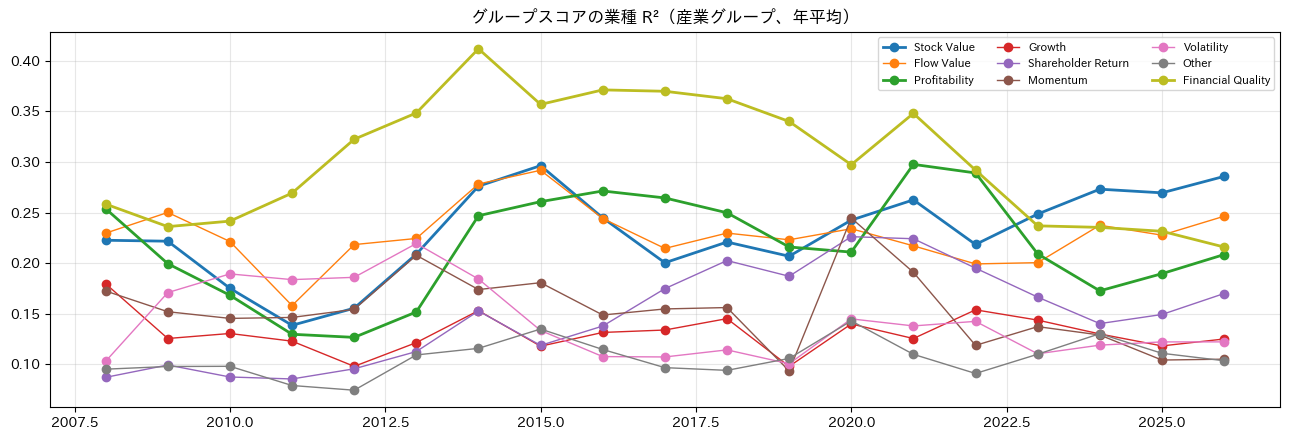

In [2]:
def tstat(s: pd.Series) -> float:
    s = s.dropna()
    return float(s.mean() / s.std() * np.sqrt(len(s))) if len(s) > 2 else np.nan


r2_group = {
    name: pd.DataFrame(
        {g: industry_variance_share(group_scores[g], lab) for g in GROUPS}
    )
    for name, lab in LABELS.items()
}
tbl = pd.DataFrame(
    {
        **{f"{name} 全期間": r.mean() for name, r in r2_group.items()},
        "産業グループ 2008–2012": r2_group["産業グループ"].loc["2008":"2012"].mean(),
        "産業グループ 2021–2026": r2_group["産業グループ"].loc["2021":].mean(),
    }
)
print("グループスコアの業種 R²（月平均）")
display(tbl.round(3))

fig, ax = plt.subplots(figsize=(13, 4.5))
r = r2_group["産業グループ"].groupby(r2_group["産業グループ"].index.year).mean()
for g in GROUPS:
    ax.plot(
        r.index,
        r[g],
        marker="o",
        linewidth=2
        if g in ("Profitability", "Stock Value", "Financial Quality")
        else 1,
        label=g,
    )
ax.set_title("グループスコアの業種 R²（産業グループ、年平均）")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

## 2. 素のまま・業種間・業種内の分位分析

各ファクター（グループスコア）を、素のまま・業種間成分・業種内成分の 3 通りで 5 分位に分け、等ウェイトユニバース平均に対する超過リターンを見る（論文の表に対応）。

In [3]:
VARIANTS = ["素のまま", "業種間", "業種内"]


def three_way(score: pd.DataFrame, lab: pd.DataFrame) -> dict[str, pd.DataFrame]:
    a, w = industry_decompose(score, lab)
    return {"素のまま": score, "業種間": a, "業種内": w}


def summarize(q: pd.DataFrame) -> dict[str, float]:
    out = {c: q[c].mean() * 100 for c in [f"Q{i}" for i in range(1, N_QUANTILES + 1)]}
    out["Q5−Q1 年率"] = q["spread"].mean() * 12
    out["t"] = tstat(q["spread"])
    return out


group_q = {}  # (分類, グループ, 種類) -> 月次の分位超過
for name, lab in LABELS.items():
    for g in GROUPS:
        for v, sc in three_way(group_scores[g], lab).items():
            group_q[(name, g, v)] = quantile_excess(sc, fwd, N_QUANTILES)

for name in LABELS:
    rows = {(g, v): summarize(group_q[(name, g, v)]) for g in GROUPS for v in VARIANTS}
    print(
        f"[{name}] グループスコア: 分位の月平均超過（%、対 EW ユニバース）と Q5−Q1（年率、t）"
    )
    display(pd.DataFrame(rows).T.round(2))

[産業グループ] グループスコア: 分位の月平均超過（%、対 EW ユニバース）と Q5−Q1（年率、t）


Q1    Q2    Q3    Q4    Q5  Q5−Q1 年率     t
Stock Value        素のまま -0.16  0.01 -0.02  0.11  0.06      0.03  0.55
                   業種間  -0.41  0.07  0.19  0.05  0.11      0.06  1.65
                   業種内   0.00 -0.07 -0.03  0.00  0.09      0.01  0.26
Flow Value         素のまま -0.67 -0.01  0.19  0.25  0.24      0.11  3.23
                   業種間  -0.31  0.01  0.23 -0.17  0.15      0.06  2.15
                   業種内  -0.48 -0.18  0.19  0.11  0.36      0.10  3.39
Profitability      素のまま -0.16 -0.07  0.08  0.16 -0.01      0.02  0.43
                   業種間  -0.11 -0.08  0.17 -0.08  0.05      0.02  0.54
                   業種内  -0.17 -0.03  0.07  0.06  0.07      0.03  0.95
Growth             素のまま  0.09  0.18  0.10  0.01 -0.38     -0.06 -2.26
                   業種間  -0.03  0.12  0.10  0.07 -0.36     -0.04 -1.20
                   業種内   0.10  0.18 -0.05 -0.06 -0.17     -0.03 -1.61
Shareholder Return 素のまま -0.53 -0.26  0.13  0.28  0.38      0.11  3.58
                   業種間  -0.42  0.16  0.03  0.11  0.20      0.07  2.41
                   業種内  -0.36 -0.21  0.11  0.12  0.34      0.08  3.29
Momentum           素のまま -0.39 -0.31 -0.13  0.29  0.54      0.11  2.63
                   業種間  -0.34 -0.13  0.10 -0.14  0.45      0.09  2.64
                   業種内  -0.31 -0.14 -0.06  0.09  0.42      0.09  2.55
Volatility         素のまま -0.50  0.02  0.16  0.15  0.18      0.08  1.84
                   業種間  -0.09 -0.02 -0.13  0.10  0.06      0.02  0.50
                   業種内  -0.48  0.05  0.13  0.18  0.12      0.07  1.99
Other              素のまま -0.07  0.01 -0.00  0.11 -0.04      0.00  0.17
                   業種間  -0.08 -0.15  0.17  0.14 -0.02      0.01  0.25
                   業種内   0.09 -0.13  0.04  0.00  0.00     -0.01 -0.46
Financial Quality  素のまま -0.21 -0.17 -0.07  0.18  0.27      0.06  1.41
                   業種間  -0.01 -0.13 -0.03  0.05  0.17      0.02  0.53
                   業種内  -0.37 -0.09  0.08  0.17  0.20      0.07  2.35

[セクター] グループスコア: 分位の月平均超過（%、対 EW ユニバース）と Q5−Q1（年率、t）


Q1    Q2    Q3    Q4    Q5  Q5−Q1 年率     t
Stock Value        素のまま -0.16  0.01 -0.02  0.11  0.06      0.03  0.55
                   業種間  -0.24 -0.07  0.30 -0.13  0.11      0.04  1.10
                   業種内  -0.10 -0.02 -0.04  0.09  0.07      0.02  0.47
Flow Value         素のまま -0.67 -0.01  0.19  0.25  0.24      0.11  3.23
                   業種間   0.08 -0.13 -0.17  0.35 -0.07     -0.02 -0.62
                   業種内  -0.64 -0.05  0.17  0.20  0.32      0.11  3.65
Profitability      素のまま -0.16 -0.07  0.08  0.16 -0.01      0.02  0.43
                   業種間   0.08 -0.01 -0.00  0.03 -0.09     -0.02 -0.53
                   業種内  -0.21 -0.05  0.06  0.20  0.01      0.03  0.85
Growth             素のまま  0.09  0.18  0.10  0.01 -0.38     -0.06 -2.26
                   業種間  -0.16  0.54 -0.11  0.15 -0.25     -0.01 -0.28
                   業種内   0.08  0.19  0.02 -0.04 -0.24     -0.04 -1.73
Shareholder Return 素のまま -0.53 -0.26  0.13  0.28  0.38      0.11  3.58
                   業種間  -0.15  0.05 -0.04  0.02  0.26      0.05  1.54
                   業種内  -0.42 -0.21 -0.01  0.26  0.39      0.10  3.56
Momentum           素のまま -0.39 -0.31 -0.13  0.29  0.54      0.11  2.63
                   業種間  -0.07 -0.16 -0.22  0.21  0.26      0.04  1.20
                   業種内  -0.38 -0.15 -0.05  0.13  0.45      0.10  2.69
Volatility         素のまま -0.50  0.02  0.16  0.15  0.18      0.08  1.84
                   業種間   0.02 -0.05  0.02  0.12  0.01     -0.00 -0.03
                   業種内  -0.41 -0.04  0.11  0.19  0.16      0.07  1.71
Other              素のまま -0.07  0.01 -0.00  0.11 -0.04      0.00  0.17
                   業種間  -0.23 -0.13  0.05  0.15  0.19      0.05  1.62
                   業種内   0.05 -0.10  0.08  0.05 -0.09     -0.02 -0.70
Financial Quality  素のまま -0.21 -0.17 -0.07  0.18  0.27      0.06  1.41
                   業種間   0.03 -0.11 -0.10 -0.14  0.27      0.03  0.68
                   業種内  -0.39 -0.04  0.13  0.16  0.14      0.06  2.14

In [4]:
lab = LABELS["産業グループ"]
rows, r2_fac = {}, {}
for r in fg.itertuples():
    sc = factors[r.factor]
    r2_fac[r.factor] = industry_variance_share(sc, lab).mean()
    row = {"グループ": r.group, "符号": r.sign, "業種 R²": r2_fac[r.factor]}
    for v, s in three_way(sc, lab).items():
        q = quantile_excess(s, fwd, N_QUANTILES)
        row[(v, "Q5−Q1")] = q["spread"].mean() * 12
        row[(v, "t")] = tstat(q["spread"])
    rows[r.factor] = row
fac_tbl = pd.DataFrame(rows).T
for c in fac_tbl.columns[2:]:
    fac_tbl[c] = fac_tbl[c].astype(float)
fac_tbl.columns = [
    c if isinstance(c, str) else f"{c[0]} {c[1]}" for c in fac_tbl.columns
]

agg = fac_tbl.drop(columns=["符号"]).groupby("グループ").mean().reindex(GROUPS)
agg["業種間 t > 2 の本数"] = (
    fac_tbl.groupby("グループ")["業種間 t"]
    .apply(lambda s: int((s > 2).sum()))
    .reindex(GROUPS)
)
agg["業種内 t > 2 の本数"] = (
    fac_tbl.groupby("グループ")["業種内 t"]
    .apply(lambda s: int((s > 2).sum()))
    .reindex(GROUPS)
)
agg["本数"] = fg.groupby("group").size().reindex(GROUPS)
print(
    "[産業グループ] ファクター単位の結果をグループ内で平均（p-ken の type 平均に対応、向きはそろえてある）"
)
display(agg.round(3))
print("[産業グループ] ファクター別（グループ順）")
display(fac_tbl.round(3))

[産業グループ] ファクター単位の結果をグループ内で平均（p-ken の type 平均に対応、向きはそろえてある）


,業種 R²,素のまま Q5−Q1,素のまま t,業種間 Q5−Q1,業種間 t,業種内 Q5−Q1,業種内 t,業種間 t > 2 の本数,業種内 t > 2 の本数,本数
グループ,,,,,,,,,,
Stock Value,0.238,0.017,0.348,0.041,1.072,0.012,0.285,0,0,2
Flow Value,0.226,0.062,2.101,0.028,1.064,0.058,2.251,5,11,18
Profitability,0.258,0.014,0.292,0.008,0.206,0.003,0.122,1,1,26
Growth,0.146,-0.028,-1.291,-0.029,-1.015,-0.020,-1.120,0,1,11
Shareholder Return,0.142,0.054,2.147,0.104,1.823,0.052,2.390,4,3,5
Momentum,0.144,0.075,2.277,0.045,1.286,0.061,2.183,2,4,9
Volatility,0.146,0.067,1.845,0.038,1.064,0.063,2.402,0,1,2
Other,0.106,0.004,0.172,0.003,0.087,-0.002,-0.097,0,0,1
Financial Quality,0.227,0.027,1.120,0.002,0.063,0.030,1.482,0,11,29


[産業グループ] ファクター別（グループ順）


,グループ,符号,業種 R²,素のまま Q5−Q1,素のまま t,業種間 Q5−Q1,業種間 t,業種内 Q5−Q1,業種内 t
bp_est,Stock Value,1,0.250,0.005,0.089,0.029,0.782,0.009,0.203
bp_act,Stock Value,1,0.226,0.030,0.608,0.053,1.362,0.015,0.367
ep_est,Flow Value,1,0.283,0.061,1.600,0.062,2.090,0.039,1.227
ep_act,Flow Value,1,0.231,0.079,2.866,0.061,2.150,0.054,2.321
dp_est,Flow Value,1,0.241,0.100,4.318,0.057,2.186,0.086,4.334
dp_act,Flow Value,1,0.204,0.123,5.662,0.094,3.707,0.101,5.386
sp_est,Flow Value,1,0.286,0.071,2.026,0.019,0.788,0.075,2.066
sp_act,Flow Value,1,0.244,0.076,1.884,0.046,1.627,0.046,1.236
ebitdaev_est,Flow Value,1,0.234,0.058,1.692,0.015,0.557,0.051,1.684
ebitdaev_act,Flow Value,1,0.239,0.069,2.550,0.049,2.035,0.046,1.902


## 3. 業種間の比率 $w$ を動かしたときの t 値

$w$ を 0（業種内）から 1（業種間）まで動かし、Q5−Q1 の t 値を見る（論文の図に対応）。破線は素のまま。

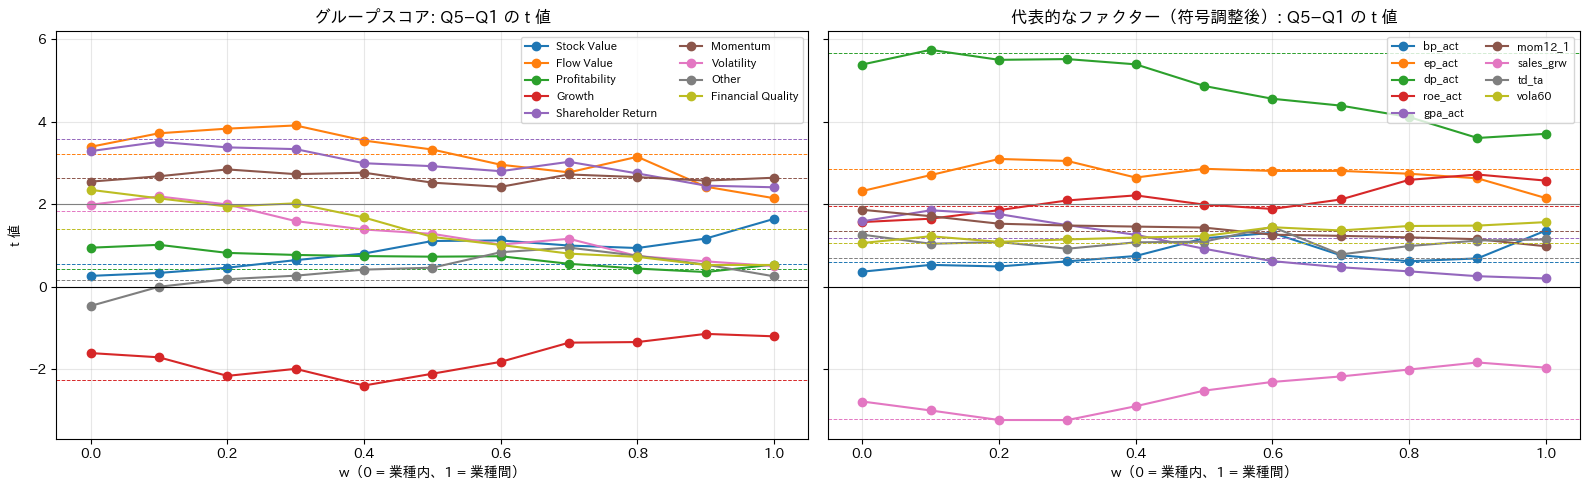

,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
Stock Value,0.26,0.34,0.46,0.65,0.81,1.11,1.12,1.00,0.94,1.17,1.65
Flow Value,3.39,3.72,3.83,3.91,3.54,3.33,2.96,2.77,3.15,2.43,2.15
Profitability,0.95,1.02,0.82,0.77,0.74,0.73,0.74,0.56,0.44,0.36,0.54
Growth,-1.61,-1.71,-2.16,-1.99,-2.39,-2.11,-1.82,-1.35,-1.34,-1.14,-1.20
Shareholder Return,3.29,3.51,3.38,3.34,2.99,2.92,2.80,3.03,2.75,2.45,2.41
Momentum,2.55,2.68,2.84,2.73,2.77,2.52,2.42,2.72,2.66,2.57,2.64
Volatility,1.99,2.19,2.00,1.59,1.39,1.28,1.02,1.16,0.75,0.62,0.50
Other,-0.46,0.00,0.18,0.27,0.42,0.46,0.84,0.95,0.75,0.54,0.25
Financial Quality,2.35,2.14,1.95,2.02,1.68,1.21,1.01,0.80,0.73,0.53,0.53
bp_act,0.37,0.53,0.49,0.62,0.75,1.18,1.31,0.76,0.62,0.69,1.36


In [5]:
W_GRID = np.round(np.linspace(0, 1, 11), 1)
PICK = [
    "bp_act",
    "ep_act",
    "dp_act",
    "roe_act",
    "gpa_act",
    "mom12_1",
    "sales_grw",
    "td_ta",
    "vola60",
]
lab = LABELS["産業グループ"]


def w_curve(score: pd.DataFrame) -> tuple[pd.Series, float]:
    a, w = industry_decompose(score, lab)
    ts = {
        x: tstat(
            quantile_excess(blend_across_within(a, w, x), fwd, N_QUANTILES)["spread"]
        )
        for x in W_GRID
    }
    return pd.Series(ts), tstat(quantile_excess(score, fwd, N_QUANTILES)["spread"])


curves_g = {g: w_curve(group_scores[g]) for g in GROUPS}
curves_f = {f: w_curve(factors[f]) for f in PICK}
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, curves, title in [
    (axes[0], curves_g, "グループスコア"),
    (axes[1], curves_f, "代表的なファクター（符号調整後）"),
]:
    for i, (n, (s, raw)) in enumerate(curves.items()):
        ax.plot(s.index, s.values, marker="o", color=f"C{i % 10}", label=n)
        ax.axhline(raw, color=f"C{i % 10}", linestyle="--", linewidth=0.7)
    ax.axhline(2, color="gray", linewidth=0.8)
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_xlabel("w（0 = 業種内、1 = 業種間）")
    ax.set_title(f"{title}: Q5−Q1 の t 値")
    ax.legend(fontsize=8, ncol=2)
axes[0].set_ylabel("t 値")
plt.tight_layout()
plt.show()
display(
    pd.DataFrame(
        {
            **{n: s for n, (s, _) in curves_g.items()},
            **{n: s for n, (s, _) in curves_f.items()},
        }
    ).T.round(2)
)

## 4. `comp_ew` を業種内に変換すると改善するか

`comp_ew` と、その 3 スリーブ（a = リビジョン、b = モメンタム + CGO、d = 規律）の業種 $R^2$ を見たうえで、次の 2 通りの業種内版を作る。

- `comp_within`: `comp_ew` 自体を業種内成分に変換
- `comp_sleeve_within`: 各スリーブを業種内成分に変換してから等ウェイト合成

In [6]:
lab = LABELS["産業グループ"]
comp = load("composite/comp_ew")
sleeves = {s: load(f"composite/{s}") for s in ["sleeve_a", "sleeve_b", "sleeve_d"]}
print(
    "業種 R²（産業グループ、月平均）:",
    {
        n: round(float(industry_variance_share(s, lab).mean()), 3)
        for n, s in {"comp_ew": comp, **sleeves}.items()
    },
)

_, comp_w = industry_decompose(comp, lab)
sl_w = [blom(industry_decompose(s, lab)[1]) for s in sleeves.values()]
scores = {
    "comp_ew": comp,
    "comp_within": blom(comp_w),
    "comp_sleeve_within": blom(
        pd.concat(sl_w).groupby(level=0).mean().reindex(univ.index).where(univ.notna())
    ),
}
returns = {
    kind: store.returns(RISK_MODEL, col, START, 202607)
    for kind, col in RETURN_KINDS.items()
}
schedule = india_tax_schedule(FPI_TYPE)


def report(name: str, score: pd.DataFrame):
    return compute_alpha_report(
        name,
        score,
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        cw_max_weight=CW_MAX_WEIGHT,
        tax_schedule=schedule,
        cost_buy=COST_BUY,
        cost_sell=COST_SELL,
        burn_in=BURN_IN,
        tax_kind="drtn",
    )


reports = {n: report(n, s) for n, s in scores.items()}


def show(reports: dict) -> None:
    first = next(iter(reports.values()))
    tbl = summary_table(reports)
    q5, sp, at = (
        first.label("ew_excess"),
        first.label("spread"),
        first.label("after_tax_excess"),
    )
    cols = [q5, q5 + " IR", "IC", "ICIR", "IC t", sp, sp + " IR"]
    for kind in ["drtn", "srtn"]:
        print(
            f"{kind}（{'配当込みトータルリターン' if kind == 'drtn' else '固有リターン'}）"
        )
        display(tbl[kind][cols].round(3))
    print("税控除後（drtn）と回転率")
    display(
        pd.concat(
            [tbl["drtn"][[at, at + " IR"]], tbl["共通"][["回転率 EW", "税ドラッグ"]]],
            axis=1,
        ).round(3)
    )


def periods(reports: dict) -> pd.DataFrame:
    P = {
        "2009–2017": ("2009-01-01", "2017-12-31"),
        "窓 2018/05–2019/08": WINDOW,
        "2020–2026": ("2020-01-01", "2026-12-31"),
    }
    rows = {}
    for n, rep in reports.items():
        r = {}
        for p, (a, b) in P.items():
            r[(p, "Q5 超過")] = rep.series["ew_excess"]["drtn"].loc[a:b].mean() * 12
            r[(p, "IC")] = rep.series["ic"]["drtn"].loc[a:b].mean()
            r[(p, "Q5−Q1")] = rep.series["spread"]["drtn"].loc[a:b].mean() * 12
        rows[n] = r
    return pd.DataFrame(rows).T


show(reports)
print("期間別（drtn、年率）")
display(periods(reports).round(3))

業種 R²（産業グループ、月平均）: {'comp_ew': 0.075, 'sleeve_a': 0.06, 'sleeve_b': 0.077, 'sleeve_d': 0.078}


drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.130,1.165,0.065,0.482,6.982,0.176,1.152
comp_within,0.115,1.041,0.056,0.473,6.848,0.153,1.087
comp_sleeve_within,0.118,1.059,0.056,0.461,6.678,0.158,1.108


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.101,1.009,0.039,0.380,5.501,0.117,1.071
comp_within,0.088,0.879,0.032,0.342,4.951,0.096,0.971
comp_sleeve_within,0.091,0.922,0.032,0.340,4.920,0.103,1.024


税控除後（drtn）と回転率


指標,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,回転率 EW,税ドラッグ
comp_ew,0.085,0.790,4.022,0.028
comp_within,0.069,0.650,4.484,0.027
comp_sleeve_within,0.071,0.668,4.329,0.028


期間別（drtn、年率）


2009–2017               窓 2018/05–2019/08               2020–2026              
                       Q5 超過     IC  Q5−Q1             Q5 超過     IC  Q5−Q1     Q5 超過     IC  Q5−Q1
comp_ew                0.161  0.077  0.184            -0.139  0.072  0.220     0.154  0.042  0.146
comp_within            0.133  0.066  0.150            -0.121  0.067  0.203     0.145  0.037  0.140
comp_sleeve_within     0.154  0.068  0.185            -0.139  0.071  0.194     0.129  0.033  0.108

## 5. 業種間成分は業種配分のシグナルになるか

業種間成分が効くグループを、**2017 年までのリターン**だけで選び、**2018 年以降**で確かめる（同じ期間で選んで評価すると、たまたま効いたものを拾うため）。

- データで選ぶ: 2008-02〜2017-12 のリターンで、業種間成分の Q5−Q1 の t 値が 1.5 以上のグループ
- 仮説で選ぶ: Financial Quality（信用サイクルの仮説。データを見る前に決めたもの）

選んだグループの業種間成分を、業種内の合成スコアに 20% 混ぜる: $\mathrm{blom}\big(0.8 \cdot z(\text{comp\_sleeve\_within}) + 0.2 \cdot z(\overline{F^{A}})\big)$。

In [7]:
IS, OOS = (
    ("2008-01-01", "2017-11-30"),
    ("2017-12-01", "2026-06-30"),
)  # スコア月（リターンは翌月）: リターン 2008-02〜2017-12 / 2018-01 以降
rows = {}
for g in GROUPS:
    s = group_q[("産業グループ", g, "業種間")]["spread"]
    rows[g] = {
        "IS Q5−Q1 年率": s.loc[IS[0] : IS[1]].mean() * 12,
        "IS t": tstat(s.loc[IS[0] : IS[1]]),
        "OOS Q5−Q1 年率": s.loc[OOS[0] : OOS[1]].mean() * 12,
        "OOS t": tstat(s.loc[OOS[0] : OOS[1]]),
        "窓 Q5−Q1": s.loc["2018-04-01":"2019-07-31"].sum(),
    }
sel = pd.DataFrame(rows).T
print(
    "業種間成分（産業グループ）の Q5−Q1: IS = リターン 2008-02〜2017-12、OOS = 2018-01〜2026-07、窓 = 2018-05〜2019-08 の合計"
)
display(sel.round(3))
picked = sel.index[sel["IS t"] >= 1.5].tolist()
print("データで選んだグループ（IS t ≥ 1.5）:", picked)

業種間成分（産業グループ）の Q5−Q1: IS = リターン 2008-02〜2017-12、OOS = 2018-01〜2026-07、窓 = 2018-05〜2019-08 の合計


,IS Q5−Q1 年率,IS t,OOS Q5−Q1 年率,OOS t,窓 Q5−Q1
Stock Value,0.065,1.059,0.060,1.433,0.043
Flow Value,0.074,1.897,0.034,1.038,-0.030
Profitability,0.016,0.296,0.024,0.499,0.061
Growth,-0.042,-0.762,-0.036,-1.181,0.046
Shareholder Return,0.101,2.081,0.044,1.221,0.126
Momentum,0.080,1.531,0.111,2.312,0.041
Volatility,0.004,0.075,0.034,0.788,0.211
Other,0.063,1.431,-0.056,-1.532,-0.123
Financial Quality,0.033,0.537,0.008,0.152,0.083


データで選んだグループ（IS t ≥ 1.5）: ['Flow Value', 'Shareholder Return', 'Momentum']


drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.130,1.165,0.065,0.482,6.982,0.176,1.152
comp_within,0.115,1.041,0.056,0.473,6.848,0.153,1.087
comp_sleeve_within,0.118,1.059,0.056,0.461,6.678,0.158,1.108
overlay_FQ,0.117,1.089,0.056,0.398,5.768,0.157,0.972
overlay_data,0.123,1.118,0.061,0.472,6.836,0.172,1.149


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.101,1.009,0.039,0.380,5.501,0.117,1.071
comp_within,0.088,0.879,0.032,0.342,4.951,0.096,0.971
comp_sleeve_within,0.091,0.922,0.032,0.340,4.920,0.103,1.024
overlay_FQ,0.090,0.929,0.032,0.314,4.545,0.103,0.898
overlay_data,0.091,0.941,0.034,0.345,5.004,0.110,1.002


税控除後（drtn）と回転率


指標,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,回転率 EW,税ドラッグ
comp_ew,0.085,0.790,4.022,0.028
comp_within,0.069,0.650,4.484,0.027
comp_sleeve_within,0.071,0.668,4.329,0.028
overlay_FQ,0.070,0.685,4.256,0.028
overlay_data,0.076,0.720,4.366,0.028


期間別（drtn、年率）


2009–2017               窓 2018/05–2019/08               2020–2026              
                       Q5 超過     IC  Q5−Q1             Q5 超過     IC  Q5−Q1     Q5 超過     IC  Q5−Q1
comp_ew                0.161  0.077  0.184            -0.139  0.072  0.220     0.154  0.042  0.146
comp_within            0.133  0.066  0.150            -0.121  0.067  0.203     0.145  0.037  0.140
comp_sleeve_within     0.154  0.068  0.185            -0.139  0.071  0.194     0.129  0.033  0.108
overlay_FQ             0.156  0.069  0.182            -0.145  0.071  0.185     0.127  0.030  0.111
overlay_data           0.165  0.074  0.206            -0.157  0.066  0.227     0.134  0.039  0.113

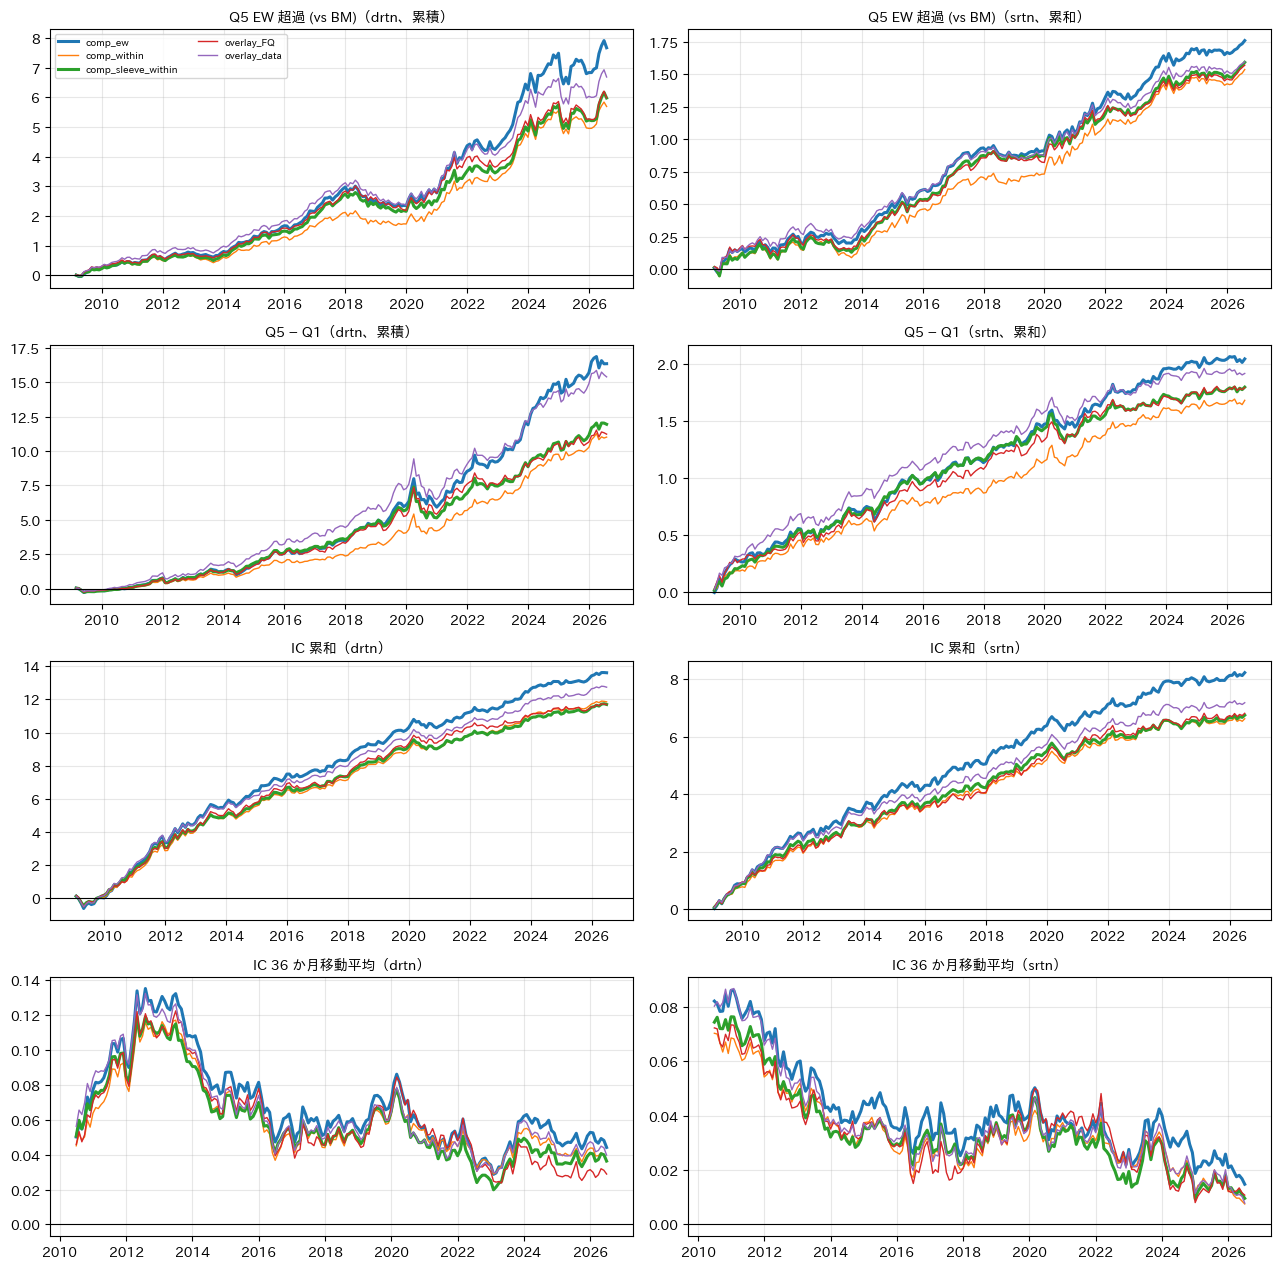

In [8]:
lab = LABELS["産業グループ"]
base_w = scores["comp_sleeve_within"]


def across_signal(groups: list[str]) -> pd.DataFrame:
    parts = [blom(industry_decompose(group_scores[g], lab)[0]) for g in groups]
    return blom(
        pd.concat(parts).groupby(level=0).mean().reindex(univ.index).where(univ.notna())
    )


def overlay(sig: pd.DataFrame, lam: float = 0.2) -> pd.DataFrame:
    # 業種間成分が無い銘柄は 0（中立）として混ぜる
    return blom(((1 - lam) * base_w + lam * sig.fillna(0.0)).where(base_w.notna()))


ov = {"overlay_FQ": overlay(across_signal(["Financial Quality"]))}
if picked:
    ov["overlay_data"] = overlay(across_signal(picked))
for n, s in ov.items():
    reports[n] = report(n, s)
show(reports)
print("期間別（drtn、年率）")
display(periods(reports).round(3))
fig = plot_cumulative(
    reports,
    metrics=("ew_excess", "ic", "spread"),
    highlight=("comp_ew", "comp_sleeve_within"),
)
plt.show()

## 6. 所見

**結論: インドのファクタープレミアムは主に業種内から来るが、例外が 3 つある（バリューの BP、ROE、モメンタム）。業種内に変換すると `comp_ew` は悪化する。
仮説で選んだ「Financial Quality の業種間成分で業種配分」は効かず、代わりに「業種モメンタム」がサンプル外でも残った。**

1. **業種で説明できる分散**（産業グループ、グループスコア）: Financial Quality 31%、Stock Value 23%、Flow Value 23%、Profitability 22%、その他は 11〜16%。
   Stock Value（18% → 26%）、Profitability（18% → 23%）、Shareholder Return（9% → 18%）は 2008〜12 年から 2021 年以降にかけて上がった。
   論文の「収益性の業種格差は大きい」「バリューの業種格差は広がっている」と同じ方向。セクター（11 区分）では説明できる割合はおよそ半分。
2. **業種内が主のグループ**: Flow Value（業種内 t 3.4 / 業種間 2.2 / 素のまま 3.2）、Volatility（2.0 / 0.5）、Financial Quality（2.4 / 0.5）。
   ファクター別でも、Financial Quality の 29 本中 11 本は業種内の t が 2 を超えるが、業種間で超えるものは 0 本。$w$ の曲線も業種内側（$w \le 0.3$）で最も高い。
3. **例外 1: バリューの BP は業種間で効く**（業種間 t 1.65 / 業種内 0.3、$w = 1$ で最大）。米国（論文）とは逆。割安なセクター（資源、PSU、金融）に賭ける形で、
   業種内の割安度は効いていない。
4. **例外 2: ROE は業種間で効く**（roe_act: 業種間 t 2.6 / 業種内 1.6、$w$ を上げるほど t が上がる）。こちらは論文と同じ。
5. **例外 3: 業種モメンタム**: モメンタムのグループは業種間・業種内とも t 2.6 程度。中身を見ると、mom1（直近 1 か月）は業種間 +9.8%（t 3.0）、
   業種内 −6.8%（t −2.2）で、**業種は 1 か月で続伸、個別銘柄は 1 か月で反転**という形がはっきり出た。リビジョンも業種間で効く（rev3r 業種間 t 2.4）。
6. **`comp_ew` を業種内に変換すると悪化する**: `comp_ew` の業種 R² はもともと 7.5% と低い。それでも業種内版は Q5 超過 13.0% → 11.5〜11.8%、IC 0.065 → 0.056、
   税控除後 8.5% → 6.9〜7.1% と下がる。残っている小さな業種成分（モメンタム・リビジョン・ROE の業種間成分）が効いている。2018〜19 年の窓の改善もわずか（Q5 超過 −13.9% → −12.1%）。
7. **業種配分のシグナル（2017 年までで選び、2018 年以降で検証）**:
   - 仮説で選んだ Financial Quality の業種間成分は、IS t 0.5、OOS t 0.2 で効かない。信用サイクルの仮説は支持されない（信用収縮の局面だけ効く可能性は残るが、平均では効かない）
   - データで選んだ 3 グループ（Flow Value、Shareholder Return、Momentum、IS t ≥ 1.5）のうち、OOS でも残ったのは **Momentum だけ**（OOS 11.1%、t 2.3）。Flow Value（t 1.0）と Shareholder Return（t 1.2）は弱まった
   - 業種内の合成に業種間成分を 20% 混ぜると、データ選択版は Q5 超過 12.3%、IC 0.061 まで戻るが、素の `comp_ew`（13.0%、0.065）は超えない
8. 注意: eiss の業種間成分（Q5−Q1 31.8%）は、業種中央値がほぼ同じ値（発行なし = 0）になって分位が偏るためで、参考外。t 値は月次の単純な t で、系列相関は補正していない。

**インド市場の仮説への含意**

- 「政策・マクロで動くセクター要因はノイズ」は、Flow Value・Volatility・Financial Quality では成り立つ。一方、バリュー（BP）はむしろセクターの割安度として効く。
  資源や PSU の割安度が、政策サイクルの中で修正される形と考えられる。
- 業種モメンタム（1 か月続伸、リビジョンの業種間成分）は、前回の「フローの持続（国内 SIP・FPI のセクター資金）」の仮説と整合する。
  インドのセクターテーマ（PSU、防衛、インフラ）は資金が順に流れ込んで続く。

**次の候補**

- `comp_ew` を業種内化するのではなく、素の `comp_ew` に業種モメンタム（mom1・リビジョンの業種間成分）を明示的に加える。銘柄の短期リバーサル（mom1 の業種内 −6.8%）との組み合わせ（業種で順張り × 銘柄で逆張り）も試す価値がある
- BP は業種内で効かないので、スリーブ d（規律）や今後のバリュー系素材は業種間（セクターの割安度）として扱うのが自然かを確認する
